In [20]:
import pandas as pd

df_a0 = pd.read_csv("df_intervals_a0.csv")
df_a30 = pd.read_csv("df_intervals_a30.csv")
df_a60 = pd.read_csv("df_intervals_a60.csv")
df_a90 = pd.read_csv("df_intervals_a90.csv")

# concatenate all dataframes
df = pd.concat([df_a0, df_a30, df_a60, df_a90], ignore_index=True)

# save concatenated dataframe
df.to_csv("df_intervals_all.csv", index=False)


In [21]:
df

,Q,alpha,mean stat,EU 95,mean mg,Z0L,Z0U,ZL,ZU
0,40,0,1.208378,0.030049,1.21365,1.212698,1.214513,1.203146,1.223436
1,60,0,0.800000,0.020756,0.80103,0.799787,0.802822,0.794075,0.808532
2,80,0,0.610000,0.019979,0.61000,0.608942,0.611079,0.604810,0.615189
3,100,0,0.496000,0.015817,0.49106,0.490588,0.499841,0.487315,0.500310
4,120,0,0.418000,0.012417,0.41998,0.419875,0.420145,0.418487,0.421086
5,40,30,1.131111,0.028619,1.13124,1.129786,1.132882,1.121363,1.141297
6,60,30,0.752667,0.023588,0.75665,0.748370,0.758435,0.745276,0.766266
7,80,30,0.520357,0.088205,0.52560,0.522277,0.529149,0.495853,0.559498
8,100,30,0.391176,0.042979,0.40056,0.399699,0.402121,0.376334,0.407824
9,120,30,0.347143,0.024601,0.34996,0.349388,0.350505,0.342976,0.355971


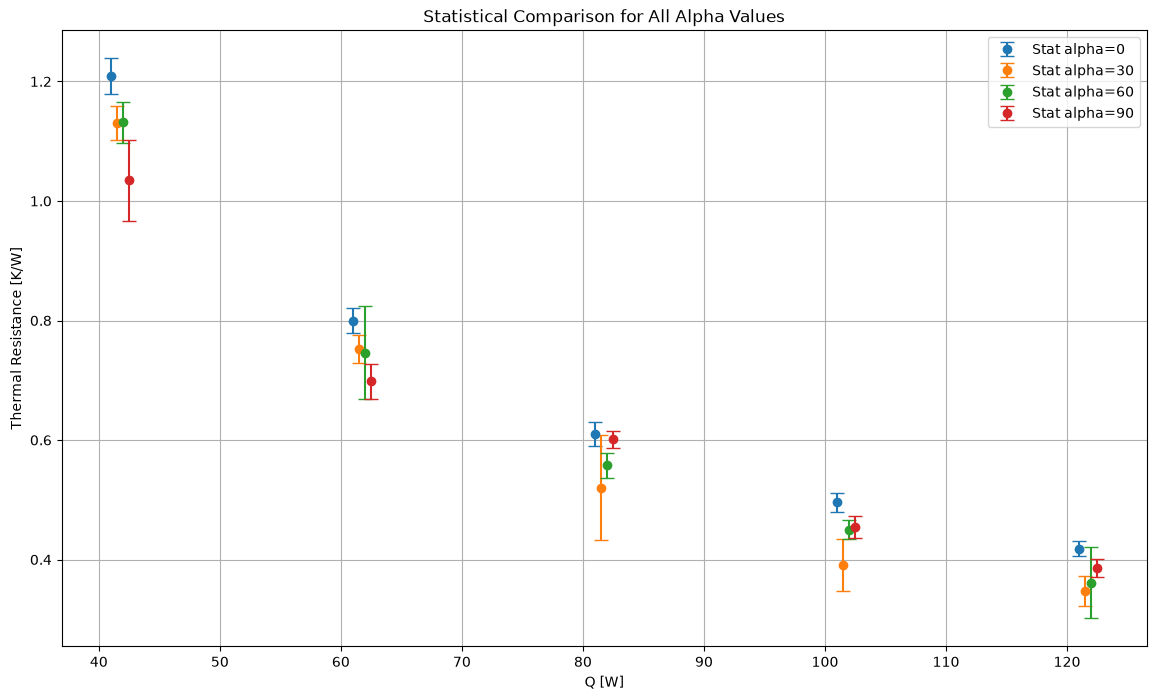

In [36]:
# statistical comparison plot for all alpha values
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
offset = 0.5
for alpha in df['alpha'].unique():
    offset = offset + 0.5
    data = df[df['alpha']==alpha]
    plt.errorbar(data["Q"] + offset, data["mean stat"], yerr=data["EU 95"], label=f"Stat alpha={alpha}", fmt="o", capsize=5)
plt.xlabel("Q [W]")
plt.ylabel("Thermal Resistance [K/W]")
plt.legend()
plt.title("Statistical Comparison for All Alpha Values")
plt.grid()
plt.show()

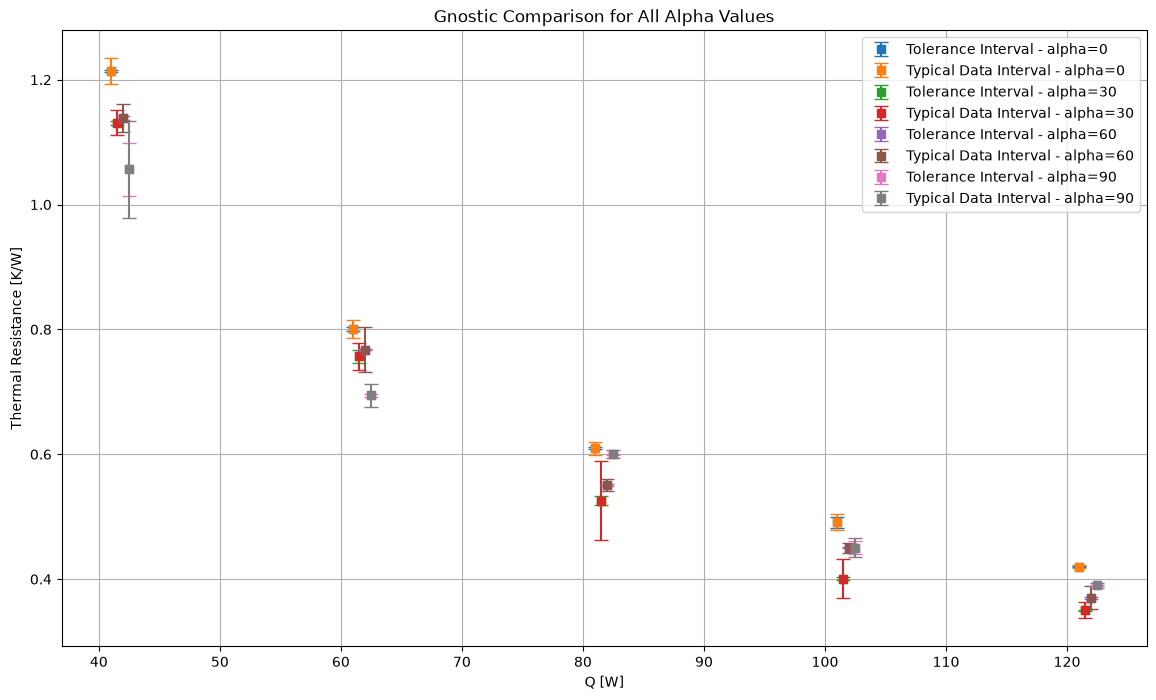

In [37]:
# gnostic comparison plot for all alpha values
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 8))
offset = 0.5
for alpha in df['alpha'].unique():
    offset = offset + 0.5
    data = df[df['alpha']==alpha]
    plt.errorbar(data["Q"] + offset, data["mean mg"], yerr=[data["Z0U"]-  data["Z0L"]], fmt="s", capsize=5, label=f"Tolerance Interval - alpha={alpha}")
    plt.errorbar(data["Q"] + offset, data["mean mg"], yerr=[data["ZU"] - data["ZL"]], fmt="s", capsize=5, label=f"Typical Data Interval - alpha={alpha}")
        
plt.xlabel("Q [W]")
plt.ylabel("Thermal Resistance [K/W]")
plt.legend()
plt.title("Gnostic Comparison for All Alpha Values")
plt.grid()
plt.show()